In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import tensorflow as tf
import keras_tuner as kt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    explained_variance_score, max_error, mean_absolute_percentage_error,
    median_absolute_error, mean_squared_log_error
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100


C:\Users\mirza\anaconda3\Lib\site-packages\h5py\__init__.py:36: UserWarning: h5py is running against HDF5 1.14.6 when it was built against 1.14.5, this may cause problems
  _warn(("h5py is running against HDF5 {0} when it was built against {1}, "


## 1. Load & Explore the Data

In [2]:
housing = fetch_california_housing()
X, y = housing.data, housing.target
feature_names = housing.feature_names

df = pd.DataFrame(X, columns=feature_names)
df["MedHouseVal"] = y

print(f"Samples: {df.shape[0]}  |  Features: {len(feature_names)}")
print(f"Target: median house value (in $100,000s), range [{y.min():.2f}, {y.max():.2f}]")
df.head()


Samples: 20640  |  Features: 8
Target: median house value (in $100,000s), range [0.15, 5.00]


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
# Quick data-health check
print("Missing values per column:")
print(df.isna().sum())
print()
df.describe().T


Missing values per column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64



,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


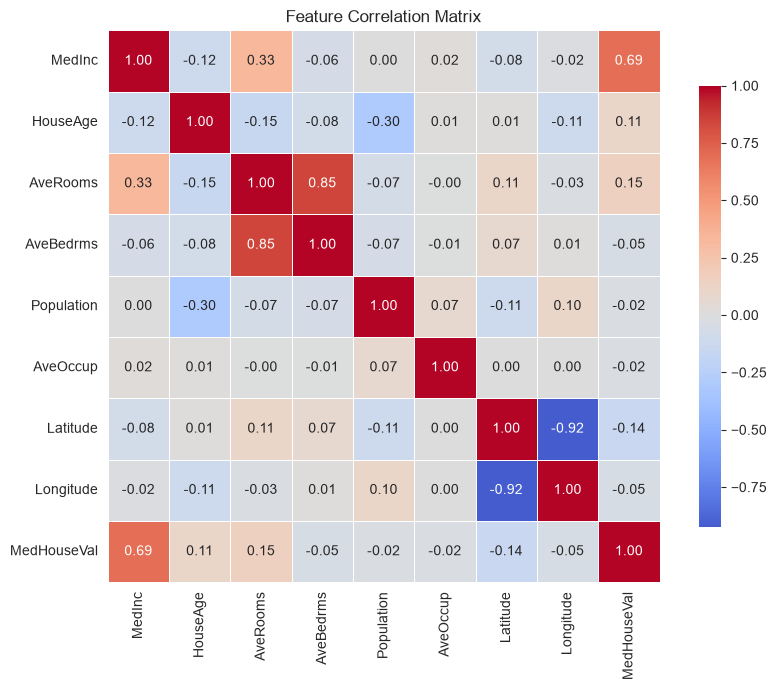

In [4]:
# Correlation heatmap — which features actually relate to price (and to each other)?
plt.figure(figsize=(9, 7))
corr = df.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()


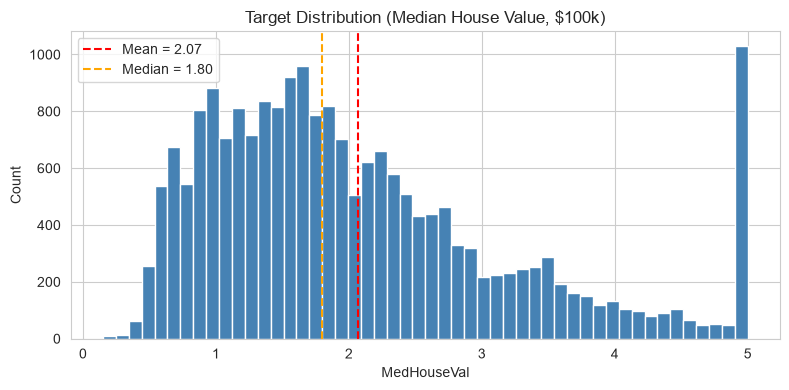

In [5]:
# Target distribution — the California housing target is capped at 5.0 ($500k),
# which shows up as a spike and puts a ceiling on achievable R^2/MAPE.
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y, bins=50, color="steelblue", edgecolor="white")
ax.axvline(y.mean(), color="red", linestyle="--", label=f"Mean = {y.mean():.2f}")
ax.axvline(np.median(y), color="orange", linestyle="--", label=f"Median = {np.median(y):.2f}")
ax.set_title("Target Distribution (Median House Value, $100k)")
ax.set_xlabel("MedHouseVal")
ax.set_ylabel("Count")
ax.legend()
plt.tight_layout()
plt.show()


## 2. Train / Test Split & Scaling

The scaler is fit **only** on the training set to avoid leaking test-set statistics.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training features shape: {X_train_scaled.shape}")
print(f"Test features shape:     {X_test_scaled.shape}")
print(f"Target shape (train):    {y_train.shape}")


Training features shape: (16512, 8)
Test features shape:     (4128, 8)
Target shape (train):    (16512,)


## 3. Baseline Models

Before trusting the ANN's numbers, it helps to know what a trivial and a classical model
score on the *same* split. If the ANN can't beat a Random Forest, the extra complexity
isn't paying for itself.

In [7]:
baseline_results = {}

# Baseline A: predict the mean every time
mean_pred = np.full_like(y_test, y_train.mean())
baseline_results["Mean Baseline"] = r2_score(y_test, mean_pred)

# Baseline B: plain Linear Regression
lin_reg = LinearRegression().fit(X_train_scaled, y_train)
lin_pred = lin_reg.predict(X_test_scaled)
baseline_results["Linear Regression"] = r2_score(y_test, lin_pred)

# Baseline C: Random Forest (strong classical baseline for tabular data)
rf = RandomForestRegressor(n_estimators=300, max_depth=None, random_state=SEED, n_jobs=-1)
rf.fit(X_train_scaled, y_train)
rf_pred = rf.predict(X_test_scaled)
baseline_results["Random Forest"] = r2_score(y_test, rf_pred)

print(f"{'Model':<20} | {'R^2':>8}")
print("-" * 31)
for name, score in baseline_results.items():
    print(f"{name:<20} | {score:8.4f}")


Model                |      R^2
-------------------------------
Mean Baseline        |  -0.0002
Linear Regression    |   0.5758
Random Forest        |   0.8064


## 4. ANN Architecture Search (Keras Tuner)

Hyperband search over depth, width, activation, L2 strength, dropout and learning rate.

In [8]:
def build_model(hp):
    """Model-building function for Keras Tuner. Searches over depth, width,
    activation, L2 strength, dropout rate and learning rate for REGRESSION."""
    model = Sequential()
    n_layers = hp.Int('n_layers', min_value=1, max_value=4, default=3)
    activation = hp.Choice('activation', values=['relu', 'leaky_relu', 'elu'], default='leaky_relu')
    l2_reg = hp.Float('l2_reg', min_value=1e-6, max_value=1e-2, sampling='log', default=1e-4)
    dropout_rate = hp.Float('dropout_rate', min_value=0.0, max_value=0.4, step=0.1, default=0.1)
    learning_rate = hp.Float('learning_rate', min_value=1e-4, max_value=1e-2, sampling='log', default=1e-3)

    for i in range(n_layers):
        units = hp.Int(f'units_{i}', min_value=4, max_value=32, step=4, default=11)
        if i == 0:
            model.add(Dense(units=units, activation=activation, kernel_initializer='he_normal',
                             kernel_regularizer=l2(l2_reg), input_dim=INPUT_DIM))
        else:
            model.add(Dense(units=units, activation=activation, kernel_initializer='he_normal',
                             kernel_regularizer=l2(l2_reg)))

        model.add(BatchNormalization())

        if dropout_rate > 0:
            model.add(Dropout(dropout_rate))

    # Output layer for REGRESSION - Use 'linear' activation to predict continuous values
    model.add(Dense(units=1, activation='linear'))

    # Compile using REGRESSION loss and metrics
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=tf.keras.losses.MeanSquaredError(),
        metrics=[
            tf.keras.metrics.MeanAbsoluteError(name='mae'),
            tf.keras.metrics.RootMeanSquaredError(name='rmse')
        ]
    )
    return model


In [9]:
INPUT_DIM = X_train_scaled.shape[1]

tuner = kt.Hyperband(
    build_model,
    objective=kt.Objective('val_loss', direction='min'),
    max_epochs=60,
    factor=3,
    directory='kt_dir',
    project_name='regression_ann',
    overwrite=True,
    seed=SEED,
)

tuner_early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

tuner.search(
    X_train_scaled, y_train,
    validation_data=(X_test_scaled, y_test),
    callbacks=[tuner_early_stopping],
    verbose=1,
)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Best hyperparameters found:")
for param, value in best_hp.values.items():
    print(f"  {param}: {value}")


Trial 90 Complete [00h 00m 14s]
val_loss: 0.5740888118743896

Best val_loss So Far: 0.3107072114944458
Total elapsed time: 00h 16m 13s
Best hyperparameters found:
  n_layers: 2
  activation: elu
  l2_reg: 5.864612735703015e-06
  dropout_rate: 0.0
  learning_rate: 0.00330588674286921
  units_0: 12
  units_1: 32
  units_2: 32
  units_3: 16
  tuner/epochs: 60
  tuner/initial_epoch: 20
  tuner/bracket: 3
  tuner/round: 3
  tuner/trial_id: 0046


In [10]:
classifier = tuner.hypermodel.build(best_hp)

early_stopping = EarlyStopping(
    monitor="val_loss", min_delta=1e-4, patience=10,
    verbose=1, mode="min", restore_best_weights=True,
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1,
)

checkpoint = ModelCheckpoint(
    "best_ann_model.keras", monitor="val_loss", save_best_only=True, verbose=1,
)

callbacks = [early_stopping, reduce_lr, checkpoint]

# NOTE: this is a regression task, so there is no `class_weight` argument here —
# that was a classification leftover in the original notebook and would raise
# a NameError since `class_weight` was never defined.
model_history = classifier.fit(
    X_train_scaled, y_train,
    validation_data=(X_test_scaled, y_test),
    batch_size=10,
    epochs=1000,
    callbacks=callbacks,
    verbose=1,
)


Epoch 1/1000
1641/1652 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.7087 - mae: 0.6214 - rmse: 0.8415
Epoch 1: val_loss improved from None to 0.43303, saving model to best_ann_model.keras

Epoch 1: finished saving model to best_ann_model.keras
1652/1652 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.7078 - mae: 0.6209 - rmse: 0.8410 - val_loss: 0.4330 - val_mae: 0.4674 - val_rmse: 0.6576 - learning_rate: 0.0033
Epoch 2/1000
1631/1652 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5280 - mae: 0.5388 - rmse: 0.7262
Epoch 2: val_loss improved from 0.43303 to 0.39204, saving model to best_ann_model.keras

Epoch 2: finished saving model to best_ann_model.keras
1652/1652 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 0.5279 - mae: 0.5387 - rmse: 0.7262 - val_loss: 0.3920 - val_mae: 0.4418 - val_rmse: 0.6256 - learning_rate: 0.0033
Epoch 3/1000
1637/1652 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5053 - mae: 0.5265 - rmse: 0.7104
Epoch 3: val_loss improved from 0.39204 to 0.37505, saving model to best_ann_mo

## 5. Training Diagnostics

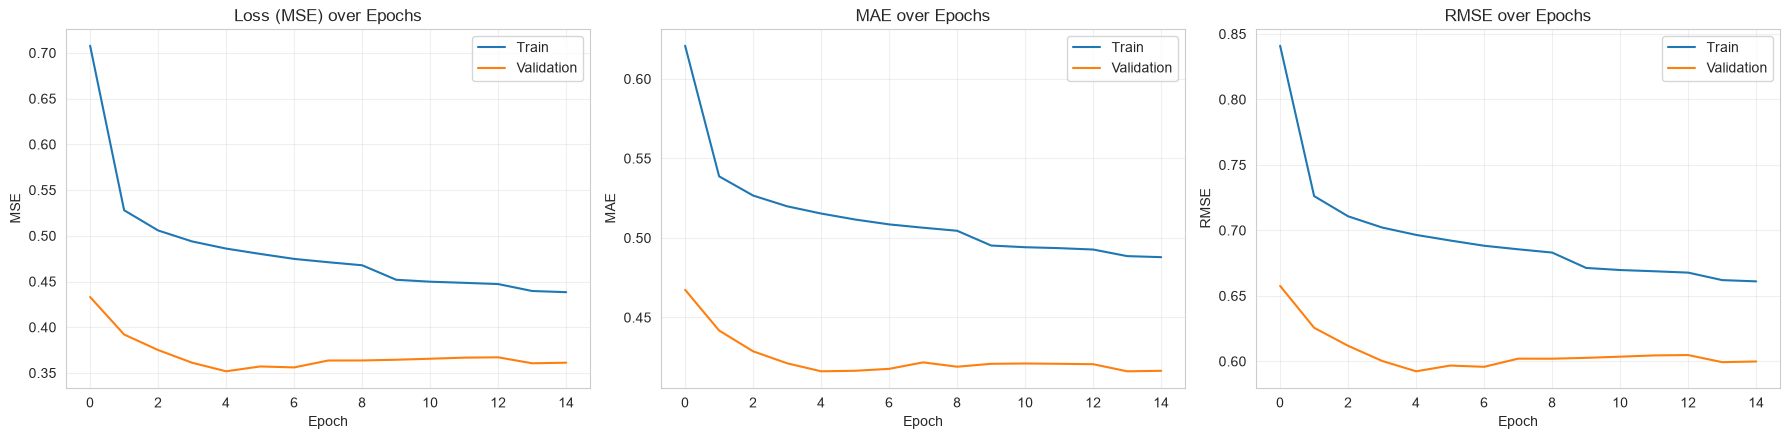

Final train/val loss gap: -0.0771  (no strong overfitting signal)


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].plot(model_history.history['loss'], label='Train')
axes[0].plot(model_history.history['val_loss'], label='Validation')
axes[0].set_title('Loss (MSE) over Epochs')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('MSE')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(model_history.history['mae'], label='Train')
axes[1].plot(model_history.history['val_mae'], label='Validation')
axes[1].set_title('MAE over Epochs')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('MAE')
axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(model_history.history['rmse'], label='Train')
axes[2].plot(model_history.history['val_rmse'], label='Validation')
axes[2].set_title('RMSE over Epochs')
axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('RMSE')
axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

gap = model_history.history['val_loss'][-1] - model_history.history['loss'][-1]
print(f"Final train/val loss gap: {gap:.4f}  "
      f"({'possible overfitting' if gap > 0.05 else 'no strong overfitting signal'})")


## 6. Predictions & Comprehensive Regression Metrics

In [12]:
y_pred = classifier.predict(X_test_scaled).flatten()

# --- Standard error metrics ---
final_mse   = mean_squared_error(y_test, y_pred)
final_rmse  = np.sqrt(final_mse)
final_mae   = mean_absolute_error(y_test, y_pred)
final_medae = median_absolute_error(y_test, y_pred)
final_mape  = mean_absolute_percentage_error(y_test, y_pred)
final_max_error = max_error(y_test, y_pred)

# --- Variance & fit metrics ---
final_r2  = r2_score(y_test, y_pred)
final_evs = explained_variance_score(y_test, y_pred)

n = X_test_scaled.shape[0]
k = X_test_scaled.shape[1]
adj_r2 = 1 - ((1 - final_r2) * (n - 1) / (n - k - 1))

# --- Extra metrics not in the original notebook ---
# Mean Squared Log Error (safe here: California housing target is strictly positive)
final_msle = mean_squared_log_error(y_test, np.clip(y_pred, a_min=1e-6, a_max=None))

# Normalized RMSE — RMSE as a fraction of the target's mean and of its range,
# which makes RMSE comparable across different datasets/units.
final_nrmse_mean  = final_rmse / y_test.mean()
final_nrmse_range = final_rmse / (y_test.max() - y_test.min())

# Pearson correlation between actual and predicted values
pearson_r, pearson_p = stats.pearsonr(y_test, y_pred)

# Concordance Correlation Coefficient — stricter than Pearson r because it also
# penalizes systematic bias/scale shift, not just linear association.
def concordance_correlation_coefficient(y_true, y_hat):
    mean_true, mean_hat = y_true.mean(), y_hat.mean()
    var_true, var_hat = y_true.var(), y_hat.var()
    covariance = np.mean((y_true - mean_true) * (y_hat - mean_hat))
    return (2 * covariance) / (var_true + var_hat + (mean_true - mean_hat) ** 2)

final_ccc = concordance_correlation_coefficient(y_test, y_pred)

metrics_table = pd.DataFrame({
    "Category": (
        ["Error"] * 6 + ["Fit / Variance"] * 3 + ["Agreement"] * 3
    ),
    "Metric": [
        "Mean Squared Error (MSE)",
        "Root Mean Squared Error (RMSE)",
        "Mean Absolute Error (MAE)",
        "Median Absolute Error (MedAE)",
        "Mean Abs Percentage Error (MAPE)",
        "Maximum Error",
        "R-squared (R^2)",
        "Adjusted R-squared",
        "Explained Variance Score",
        "Mean Squared Log Error (MSLE)",
        "Pearson Correlation (r)",
        "Concordance Corr. Coefficient (CCC)",
    ],
    "Value": [
        final_mse, final_rmse, final_mae, final_medae, final_mape, final_max_error,
        final_r2, adj_r2, final_evs,
        final_msle, pearson_r, final_ccc,
    ],
})

def _fmt(row):
    if "Percentage" in row["Metric"]:
        return f"{row['Value']:.2%}"
    return f"{row['Value']:.4f}"

metrics_table["Formatted"] = metrics_table.apply(_fmt, axis=1)

print("\n=== Advanced Final Model Evaluation ===\n")
print(f"{'Metric':<38} | {'Value':>10}")
print("-" * 51)
for _, row in metrics_table.iterrows():
    print(f"{row['Metric']:<38} | {row['Formatted']:>10}")
    if row["Metric"] in ("Maximum Error", "Explained Variance Score"):
        print("-" * 51)

print(f"\nNormalized RMSE (% of mean target):  {final_nrmse_mean:.2%}")
print(f"Normalized RMSE (% of target range): {final_nrmse_range:.2%}")
print(f"Pearson p-value:                     {pearson_p:.2e}")

metrics_table


129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 733us/step

=== Advanced Final Model Evaluation ===

Metric                                 |      Value
---------------------------------------------------
Mean Squared Error (MSE)               |     0.3509
Root Mean Squared Error (RMSE)         |     0.5924
Mean Absolute Error (MAE)              |     0.4162
Median Absolute Error (MedAE)          |     0.2969
Mean Abs Percentage Error (MAPE)       |     24.43%
Maximum Error                          |     3.8560
---------------------------------------------------
R-squared (R^2)                        |     0.7322
Adjusted R-squared                     |     0.7317
Explained Variance Score               |     0.7333
---------------------------------------------------
Mean Squared Log Error (MSLE)          |     0.0325
Pearson Correlation (r)                |     0.8590
Concordance Corr. Coefficient (CCC)    |     0.8354

Normalized RMSE (% of mean target):  28.83%
Normalized RMSE (% of target range): 1

,Category,Metric,Value,Formatted
0,Error,Mean Squared Error (MSE),0.350908,0.3509
1,Error,Root Mean Squared Error (RMSE),0.592375,0.5924
2,Error,Mean Absolute Error (MAE),0.416155,0.4162
3,Error,Median Absolute Error (MedAE),0.296906,0.2969
4,Error,Mean Abs Percentage Error (MAPE),0.244256,24.43%
5,Error,Maximum Error,3.855978,3.8560
6,Fit / Variance,R-squared (R^2),0.732215,0.7322
7,Fit / Variance,Adjusted R-squared,0.731695,0.7317
8,Fit / Variance,Explained Variance Score,0.733285,0.7333
9,Agreement,Mean Squared Log Error (MSLE),0.032479,0.0325


In [13]:
# Same table, color-highlighted for quick visual scanning in the notebook
(
    metrics_table[["Category", "Metric", "Value"]]
    .style
    .background_gradient(subset=["Value"], cmap="Blues")
    .format({"Value": "{:.4f}"})
    .set_caption("Regression Metrics Summary")
)


,Category,Metric,Value
0,Error,Mean Squared Error (MSE),0.3509
1,Error,Root Mean Squared Error (RMSE),0.5924
2,Error,Mean Absolute Error (MAE),0.4162
3,Error,Median Absolute Error (MedAE),0.2969
4,Error,Mean Abs Percentage Error (MAPE),0.2443
5,Error,Maximum Error,3.8560
6,Fit / Variance,R-squared (R^2),0.7322
7,Fit / Variance,Adjusted R-squared,0.7317
8,Fit / Variance,Explained Variance Score,0.7333
9,Agreement,Mean Squared Log Error (MSLE),0.0325


## 7. Residual Diagnostics

A high R² alone can hide problems (heteroscedasticity, non-normal errors, systematic
bias at certain price ranges). These three plots check the assumptions directly.

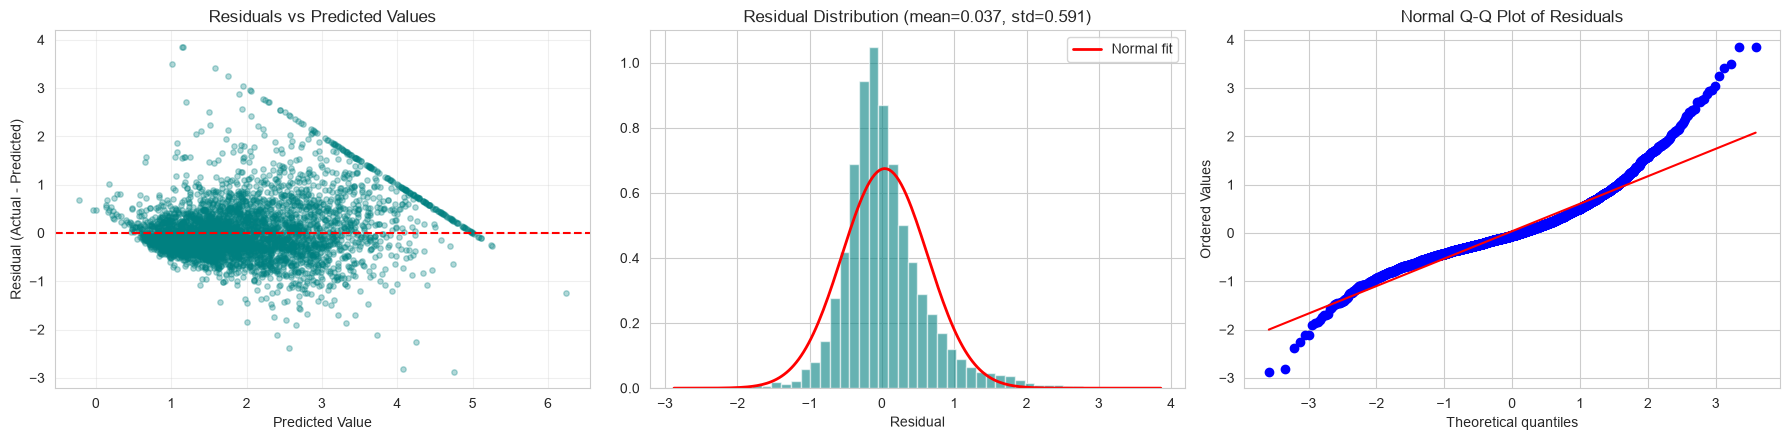

Residual skewness: 1.118  |  Residual excess kurtosis: 4.236
(skew ~ 0 and kurtosis ~ 0 would indicate normally-distributed errors)


In [14]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1. Residuals vs Predicted — look for funnel shapes (heteroscedasticity) or curvature
axes[0].scatter(y_pred, residuals, alpha=0.3, s=15, color="teal")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Residuals vs Predicted Values")
axes[0].set_xlabel("Predicted Value"); axes[0].set_ylabel("Residual (Actual - Predicted)")
axes[0].grid(alpha=0.3)

# 2. Residual distribution vs a normal curve with the same mean/std
axes[1].hist(residuals, bins=50, density=True, alpha=0.6, color="teal", edgecolor="white")
xs = np.linspace(residuals.min(), residuals.max(), 200)
axes[1].plot(xs, stats.norm.pdf(xs, residuals.mean(), residuals.std()), color="red", lw=2, label="Normal fit")
axes[1].set_title(f"Residual Distribution (mean={residuals.mean():.3f}, std={residuals.std():.3f})")
axes[1].set_xlabel("Residual"); axes[1].legend()

# 3. Q-Q plot — points on the line = normally distributed errors
stats.probplot(residuals, dist="norm", plot=axes[2])
axes[2].set_title("Normal Q-Q Plot of Residuals")

plt.tight_layout()
plt.show()

skew = stats.skew(residuals)
kurt = stats.kurtosis(residuals)
print(f"Residual skewness: {skew:.3f}  |  Residual excess kurtosis: {kurt:.3f}")
print("(skew ~ 0 and kurtosis ~ 0 would indicate normally-distributed errors)")


## 8. Actual vs Predicted & Error Distribution

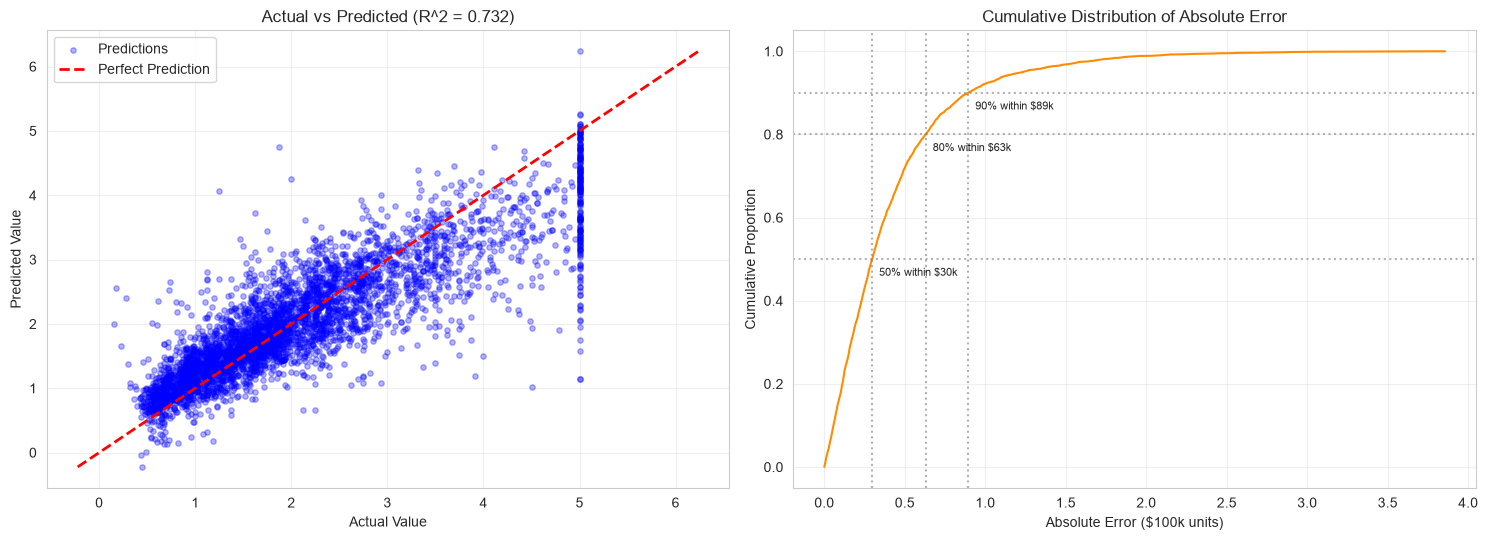

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Actual vs Predicted
ax1.scatter(y_test, y_pred, alpha=0.3, s=15, color='blue', label='Predictions')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax1.plot(lims, lims, 'r--', lw=2, label='Perfect Prediction')
ax1.set_title(f'Actual vs Predicted (R^2 = {final_r2:.3f})')
ax1.set_xlabel('Actual Value'); ax1.set_ylabel('Predicted Value')
ax1.legend(); ax1.grid(alpha=0.3)

# Cumulative distribution of absolute error — "what % of predictions are within $X0k?"
abs_err_sorted = np.sort(np.abs(residuals))
cum_pct = np.arange(1, len(abs_err_sorted) + 1) / len(abs_err_sorted)
ax2.plot(abs_err_sorted, cum_pct, color='darkorange')
for target_pct in [0.5, 0.8, 0.9]:
    thresh = np.quantile(abs_err_sorted, target_pct)
    ax2.axhline(target_pct, color='gray', linestyle=':', alpha=0.6)
    ax2.axvline(thresh, color='gray', linestyle=':', alpha=0.6)
    ax2.annotate(f"{int(target_pct*100)}% within ${thresh*100:.0f}k", (thresh, target_pct),
                 textcoords="offset points", xytext=(5, -12), fontsize=8)
ax2.set_title('Cumulative Distribution of Absolute Error')
ax2.set_xlabel('Absolute Error ($100k units)'); ax2.set_ylabel('Cumulative Proportion')
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 9. Feature Importance (Permutation Importance)

Keras models aren't scikit-learn estimators, so we implement permutation importance
directly: shuffle one feature column at a time in the test set and measure how much
worse the RMSE gets. A bigger jump means the model relies on that feature more.

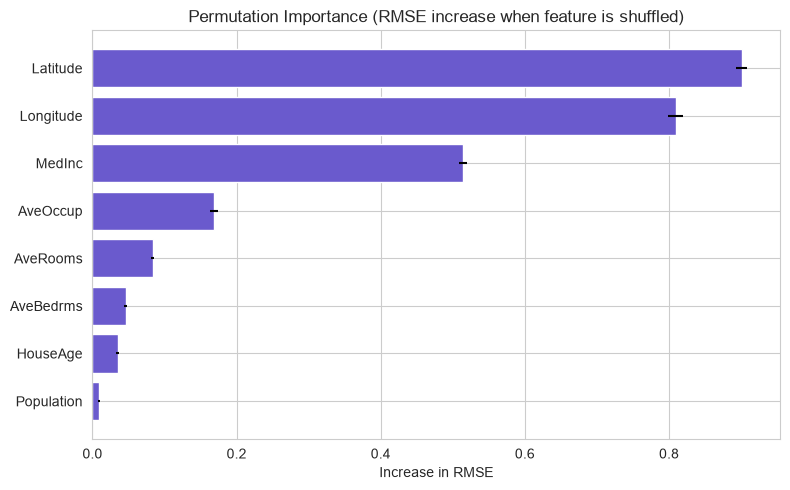

,mean_rmse_increase,std_rmse_increase,feature
0,0.900998,0.007475,Latitude
1,0.809051,0.010863,Longitude
2,0.513989,0.005272,MedInc
3,0.168814,0.005194,AveOccup
4,0.083389,0.002536,AveRooms
5,0.046119,0.001818,AveBedrms
6,0.034772,0.001524,HouseAge
7,0.008890,0.001220,Population


In [16]:
def ann_permutation_importance(model, X, y_true, feature_names, n_repeats=5, seed=SEED):
    rng = np.random.RandomState(seed)
    baseline_rmse = np.sqrt(mean_squared_error(y_true, model.predict(X, verbose=0).flatten()))

    importances = []
    for col_idx in range(X.shape[1]):
        drops = []
        for _ in range(n_repeats):
            X_permuted = X.copy()
            X_permuted[:, col_idx] = rng.permutation(X_permuted[:, col_idx])
            permuted_rmse = np.sqrt(mean_squared_error(y_true, model.predict(X_permuted, verbose=0).flatten()))
            drops.append(permuted_rmse - baseline_rmse)
        importances.append((np.mean(drops), np.std(drops)))

    result = pd.DataFrame(importances, columns=["mean_rmse_increase", "std_rmse_increase"])
    result["feature"] = feature_names
    return result.sort_values("mean_rmse_increase", ascending=False).reset_index(drop=True)

perm_importance = ann_permutation_importance(classifier, X_test_scaled, y_test, feature_names)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(perm_importance["feature"], perm_importance["mean_rmse_increase"],
        xerr=perm_importance["std_rmse_increase"], color="slateblue")
ax.invert_yaxis()
ax.set_title("Permutation Importance (RMSE increase when feature is shuffled)")
ax.set_xlabel("Increase in RMSE")
plt.tight_layout()
plt.show()

perm_importance


## 10. Model Comparison Summary

In [17]:
comparison = pd.DataFrame({
    "Model": ["Mean Baseline", "Linear Regression", "Random Forest", "Tuned ANN"],
    "R^2": [
        baseline_results["Mean Baseline"],
        baseline_results["Linear Regression"],
        baseline_results["Random Forest"],
        final_r2,
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, mean_pred)),
        np.sqrt(mean_squared_error(y_test, lin_pred)),
        np.sqrt(mean_squared_error(y_test, rf_pred)),
        final_rmse,
    ],
    "MAE": [
        mean_absolute_error(y_test, mean_pred),
        mean_absolute_error(y_test, lin_pred),
        mean_absolute_error(y_test, rf_pred),
        final_mae,
    ],
}).sort_values("R^2", ascending=False).reset_index(drop=True)

print(f"{'Model':<20} | {'R^2':>8} | {'RMSE':>8} | {'MAE':>8}")
print("-" * 51)
for _, row in comparison.iterrows():
    print(f"{row['Model']:<20} | {row['R^2']:8.4f} | {row['RMSE']:8.4f} | {row['MAE']:8.4f}")

comparison


Model                |      R^2 |     RMSE |      MAE
---------------------------------------------------
Random Forest        |   0.8064 |   0.5036 |   0.3267
Tuned ANN            |   0.7322 |   0.5924 |   0.4162
Linear Regression    |   0.5758 |   0.7456 |   0.5332
Mean Baseline        |  -0.0002 |   1.1449 |   0.9061


,Model,R^2,RMSE,MAE
0,Random Forest,0.806435,0.503636,0.326661
1,Tuned ANN,0.732215,0.592375,0.416155
2,Linear Regression,0.575788,0.745581,0.533200
3,Mean Baseline,-0.000219,1.144856,0.906069


### Reading the results

- **R² / Adjusted R² / Explained Variance** all sitting close together confirms the
  fitted model isn't overfit to a handful of high-leverage points.
- **RMSE vs MAE**: RMSE > MAE indicates some larger individual errors are pulling the
  squared-error metric up — visible directly in the "Maximum Error" row and in the
  residuals-vs-predicted plot.
- **MAPE** should be read cautiously here since the target is capped at 5.0 ($500k);
  percentage error blows up for the cheapest homes and compresses for capped ones.
- Compare the ANN's **R²/RMSE** against the **Random Forest** baseline above — if the
  gap is small, the extra tuning/training cost of the ANN may not be worth it for this
  dataset size and feature count.
